In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [30]:
#### INPUT PATH AND LOAD DATA
INPUT_FOLDER = 'tris\\fd_push_1qrt_rod_dats'
r0_values = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 
             16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31]
k_values = [0.25]
seed = [1, 2, 3, 4]


dfs = {}  # dfs[k][r0][seed] = dataframe

for k in k_values:
    k_tag = f"{int(round(k * 100)):03d}"   # 0.35 -> "035", 0.45 -> "045"
    dfs[k] = {}

    for r0 in r0_values:
        dfs[k][r0] = {}
        for s in seed:
            path = os.path.join(INPUT_FOLDER, f"obs_K_{k_tag}_r0_{r0}_seed_{s}.dat")

            dfs[k][r0][s] = pd.read_csv(
                path,
                sep=r"\s+",          
                header=None,
                names=["step", "dist", "force_mag", "hbond"]
            )

In [ ]:
#### PLOTTING H-BONDS VS TIME FOR DIFFERENT r0 AND SEED VALUES
#raise SystemExit  # stops this cell immediately

for k in k_values:
    fig, ax = plt.subplots(figsize=(8,6), dpi=500)

    if k not in dfs:
        continue

    for r0 in r0_values:
        if r0 not in dfs[k]:
            continue
        for s, df in dfs[k][r0].items():
            ax.plot(df["step"], df["hbond"],
                    alpha=0.7, linewidth=0.5,
                    label=f"r0={r0}, seed={s}")

    ax.set_title(f"H-bonds vs time (K={k})", fontsize=14)
    ax.set_xlabel("EPOCHS", fontsize=14)
    ax.set_ylabel("Number of H-Bonds", fontsize=14)

    # With many curves, legend can get huge; you can comment it out or shrink it:
    ax.legend(fontsize=7, ncol=2, frameon=True)

    plt.show()

C:\Users\Tristan\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


In [ ]:
def steady_cutoff_by_hbonds(df,
                            tail_frac=0.10,
                            band=3.0,
                            min_stay=100000,
                            ):
    """
    Returns cutoff step where steady state begins, based on hbond convergence.
    df must have columns: 'step', 'hbond' (sorted by step).
    """
    d = df[["step", "hbond"]].dropna().sort_values("step").reset_index(drop=True)
    n = len(d)
    if n == 0:
        return None

    tail_n = int(n * tail_frac)
    plateau = d["hbond"].iloc[-tail_n:].median()  # robust plateau estimate

    in_band = (d["hbond"] >= plateau - band) & (d["hbond"] <= plateau + band)

    # Find earliest index i such that stable is True for the next min_stay points
    stable_run = in_band.rolling(min_stay, min_periods=min_stay).sum() >= min_stay
    idx = stable_run.idxmax() if stable_run.any() else None

    if idx is None:
        # fallback: if never "stays", cut at start of tail window
        return int(d["step"].iloc[-tail_n])

    # rolling window marks the END of the first full stable block; shift back
    start_idx = max(0, idx - (min_stay - 1))
    return int(d["step"].iloc[start_idx])

C:\Users\Tristan\AppData\Local\Temp\ipykernel_9300\3647873057.py:49: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\Tristan\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


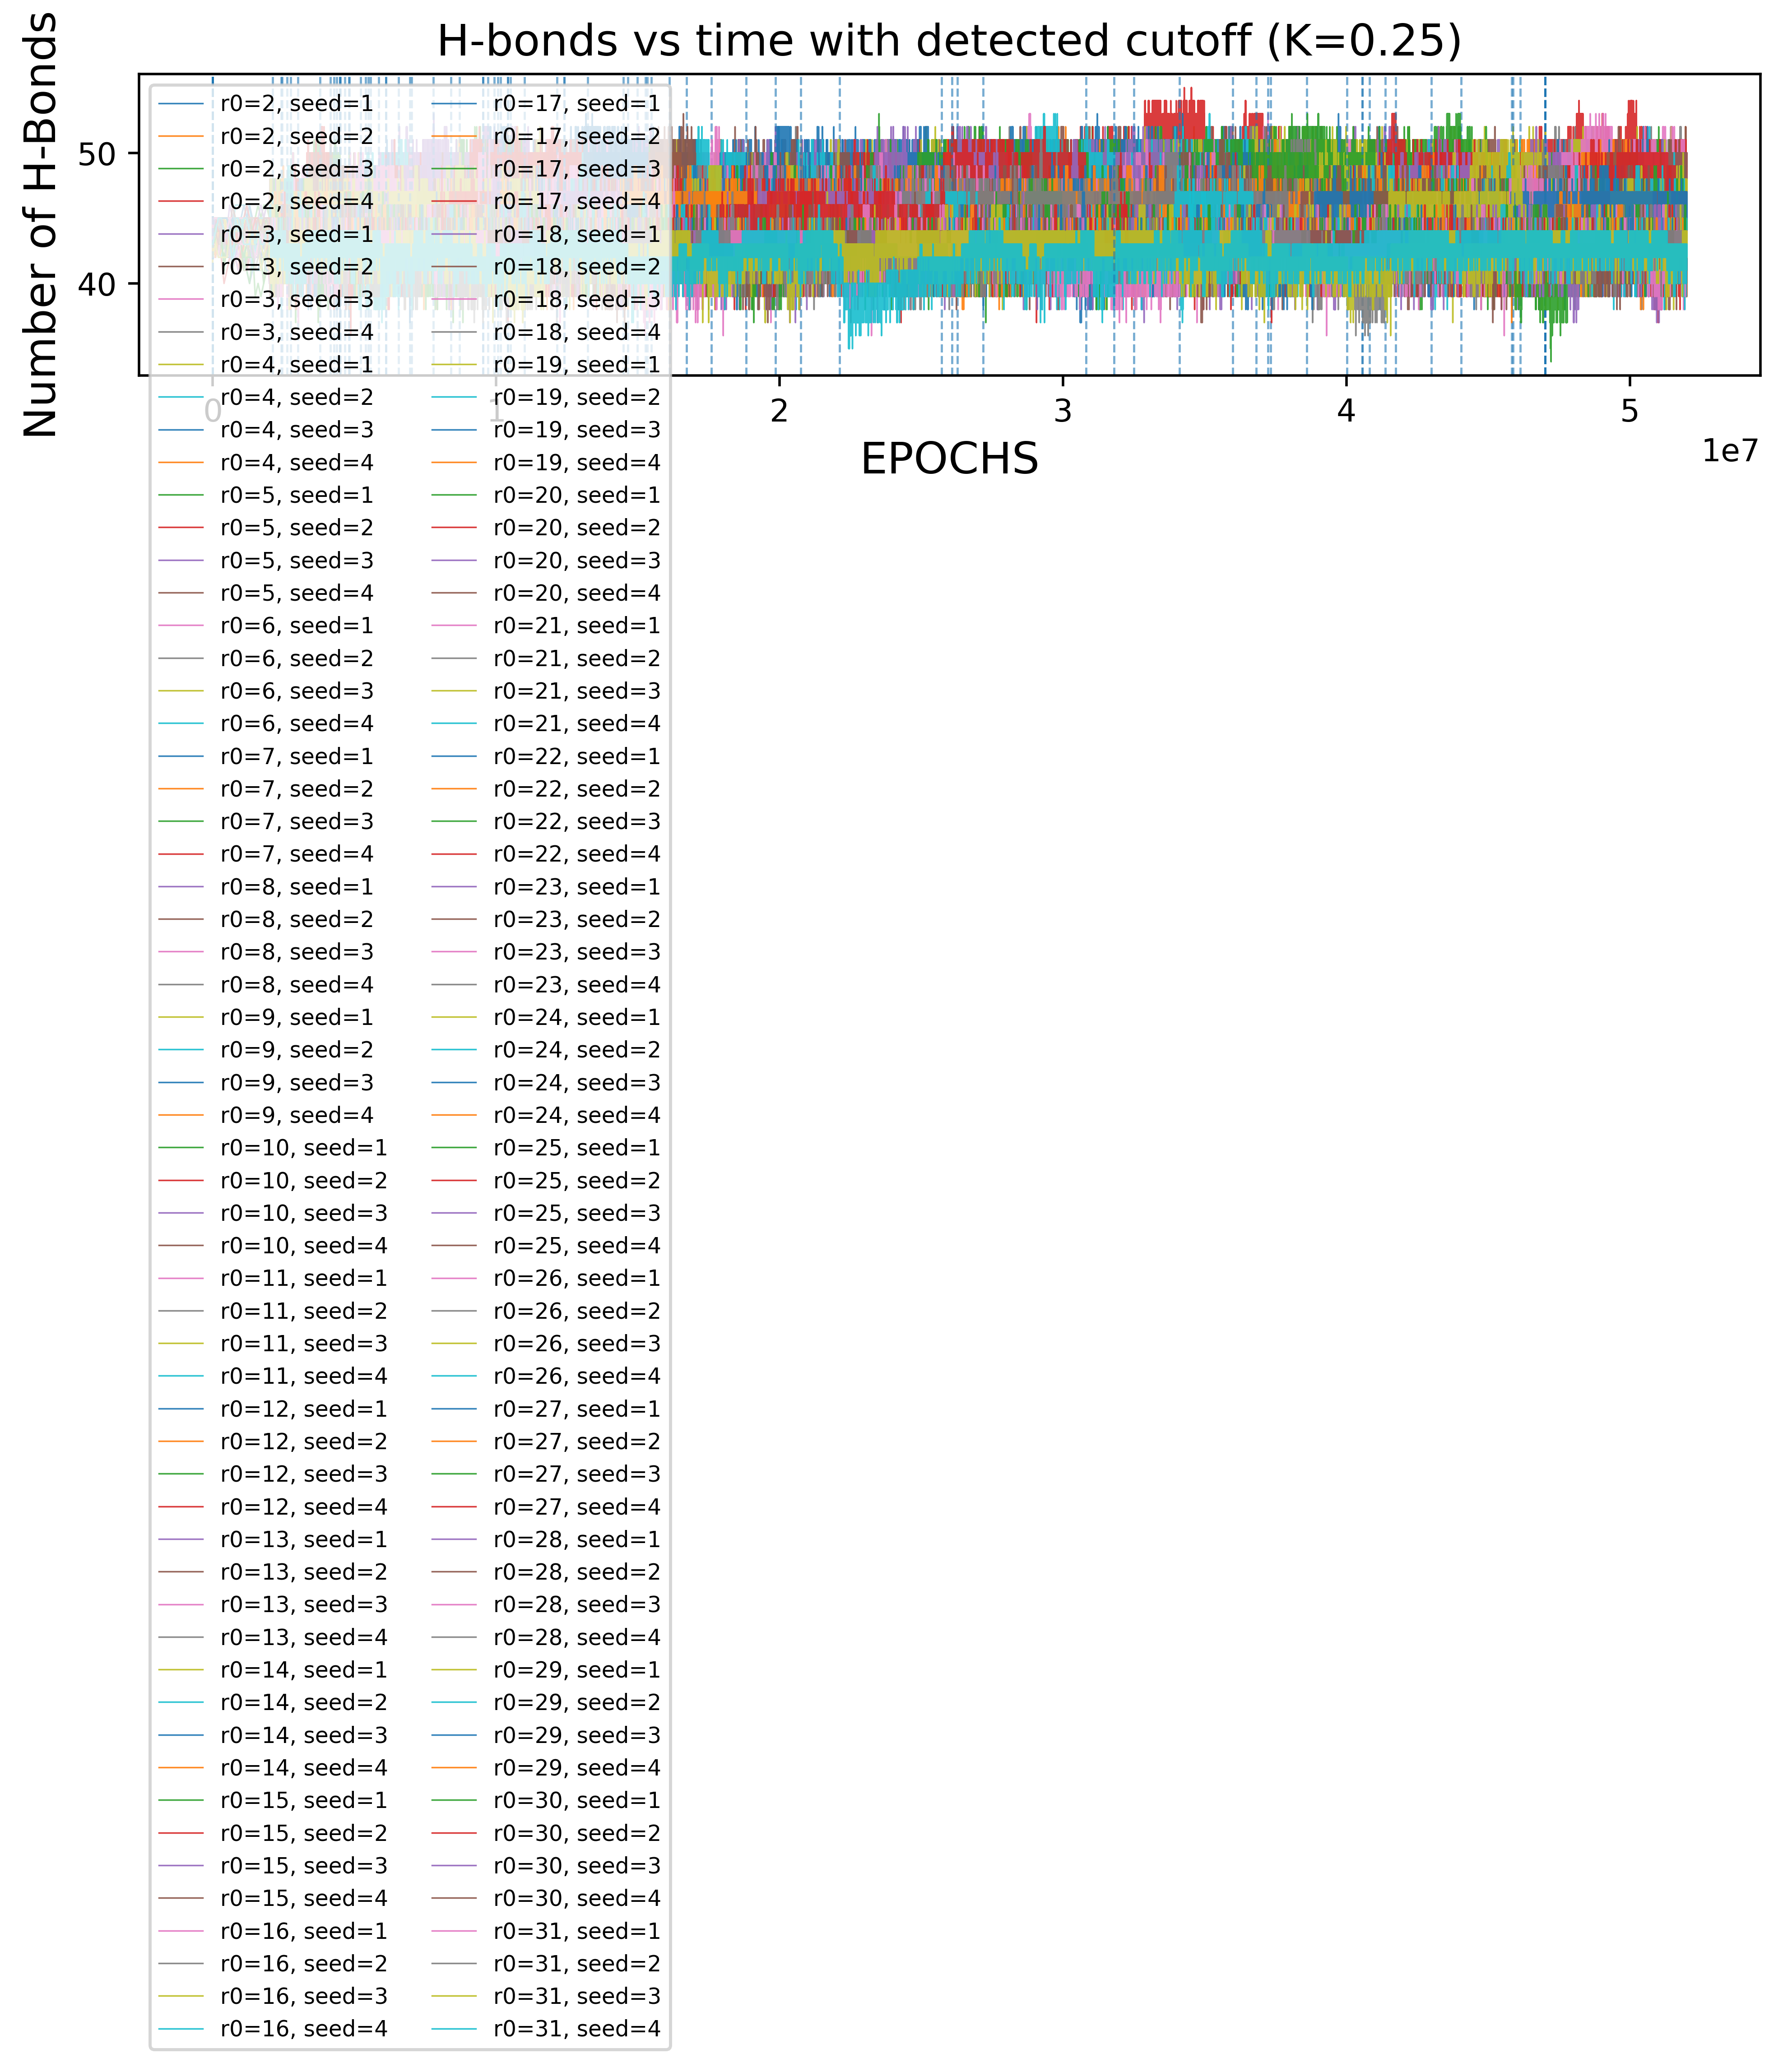

In [ ]:
import matplotlib.pyplot as plt

source = dfs

# Parameters for cutoff detection
TAIL_FRAC = 0.10
BAND = 4.0
MIN_STAY_STEPS = 5000  # adjust (e.g. 1e6 or 2e6)

cutoffs = {}      # cutoffs[k][r0][seed] = cutoff_step
dfs_ss = {}       # steady-state cropped dfs: dfs_ss[k][r0][seed]

for k, by_r0 in source.items():
    cutoffs[k] = {}
    dfs_ss[k] = {}
    for r0, by_seed in by_r0.items():
        cutoffs[k][r0] = {}
        dfs_ss[k][r0] = {}
        for s, df in by_seed.items():
            c = steady_cutoff_by_hbonds(
                df,
                tail_frac=TAIL_FRAC,
                band=BAND,
                min_stay=MIN_STAY_STEPS,
            )
            cutoffs[k][r0][s] = c
            dfs_ss[k][r0][s] = df[df["step"] >= c].reset_index(drop=True)

# ---- Plot hbonds time series with vertical cutoff lines (one figure per k) ----
#raise SystemExit  # stops this cell immediately

for k, by_r0 in source.items():
    fig, ax = plt.subplots(figsize=(8, 6), dpi=500)

    for r0, by_seed in by_r0.items():
        for s, df in by_seed.items():
            ax.plot(df["step"], df["hbond"], linewidth=0.5, alpha=0.9, label=f"r0={r0}, seed={s}")

            c = cutoffs[k][r0][s]
            ax.axvline(c, linestyle="--", linewidth=0.7, alpha=0.6)

    ax.set_title(f"H-bonds vs time with detected cutoff (K={k})", fontsize=14)
    ax.set_xlabel("EPOCHS", fontsize=14)
    ax.set_ylabel("Number of H-Bonds", fontsize=14)

    
    ax.legend(fontsize=7, ncol=2, frameon=True)

    plt.tight_layout()
    plt.show()

In [ ]:
#### BASIC STATISTICS OF STEADY STATE REGION
import numpy as np
import pandas as pd

stats_data = []
for k, by_r0 in dfs_ss.items():
    for r0 in r0_values:
        if r0 not in by_r0:
            continue
        for s, df in by_r0[r0].items():

            # signed force: +|F| if dist > r0, -|F| if dist < r0
            # np.sign gives -1, 0, +1; equality -> 0 (force becomes 0 at exact r0)
            signed_force = np.sign(df["dist"].to_numpy() - r0) * df["force_mag"].to_numpy()

            stats_data.append({
                "k": k,
                "r_0": float(r0),
                "seed": int(s),

                "F mean": signed_force.mean(),
                "F std": signed_force.std(ddof=0),

                "|F| mean": df["force_mag"].mean(),
                "|F| std": df["force_mag"].std(ddof=0),

                "dist mean": df["dist"].mean(),
                "dist std": df["dist"].std(ddof=0),
                "hbonds mean": df["hbond"].mean(),
            })

stats_df = pd.DataFrame(stats_data).sort_values(["k", "r_0", "seed"])
print(stats_df)

        k   r_0  seed    F mean     F std  |F| mean   |F| std  dist mean  \
0    0.25   2.0     1  0.171890  0.137707  0.184724  0.119943   2.687559   
1    0.25   2.0     2  0.167367  0.137228  0.181067  0.118566   2.669469   
2    0.25   2.0     3  0.169440  0.137336  0.182993  0.118679   2.677762   
3    0.25   2.0     4  0.036593  0.114433  0.097488  0.070214   2.146374   
4    0.25   3.0     1  0.116152  0.143267  0.148979  0.108729   3.464607   
..    ...   ...   ...       ...       ...       ...       ...        ...   
115  0.25  30.0     4 -0.287955  0.157237  0.291030  0.151469  28.848181   
116  0.25  31.0     1 -0.303612  0.150621  0.306041  0.145621  29.785554   
117  0.25  31.0     2 -0.307964  0.150128  0.310170  0.145516  29.768144   
118  0.25  31.0     3 -0.312642  0.158373  0.314701  0.154241  29.749431   
119  0.25  31.0     4 -0.323419  0.150956  0.325063  0.147384  29.706323   

     dist std  hbonds mean  
0    0.550829    47.122804  
1    0.548910    46.840712  


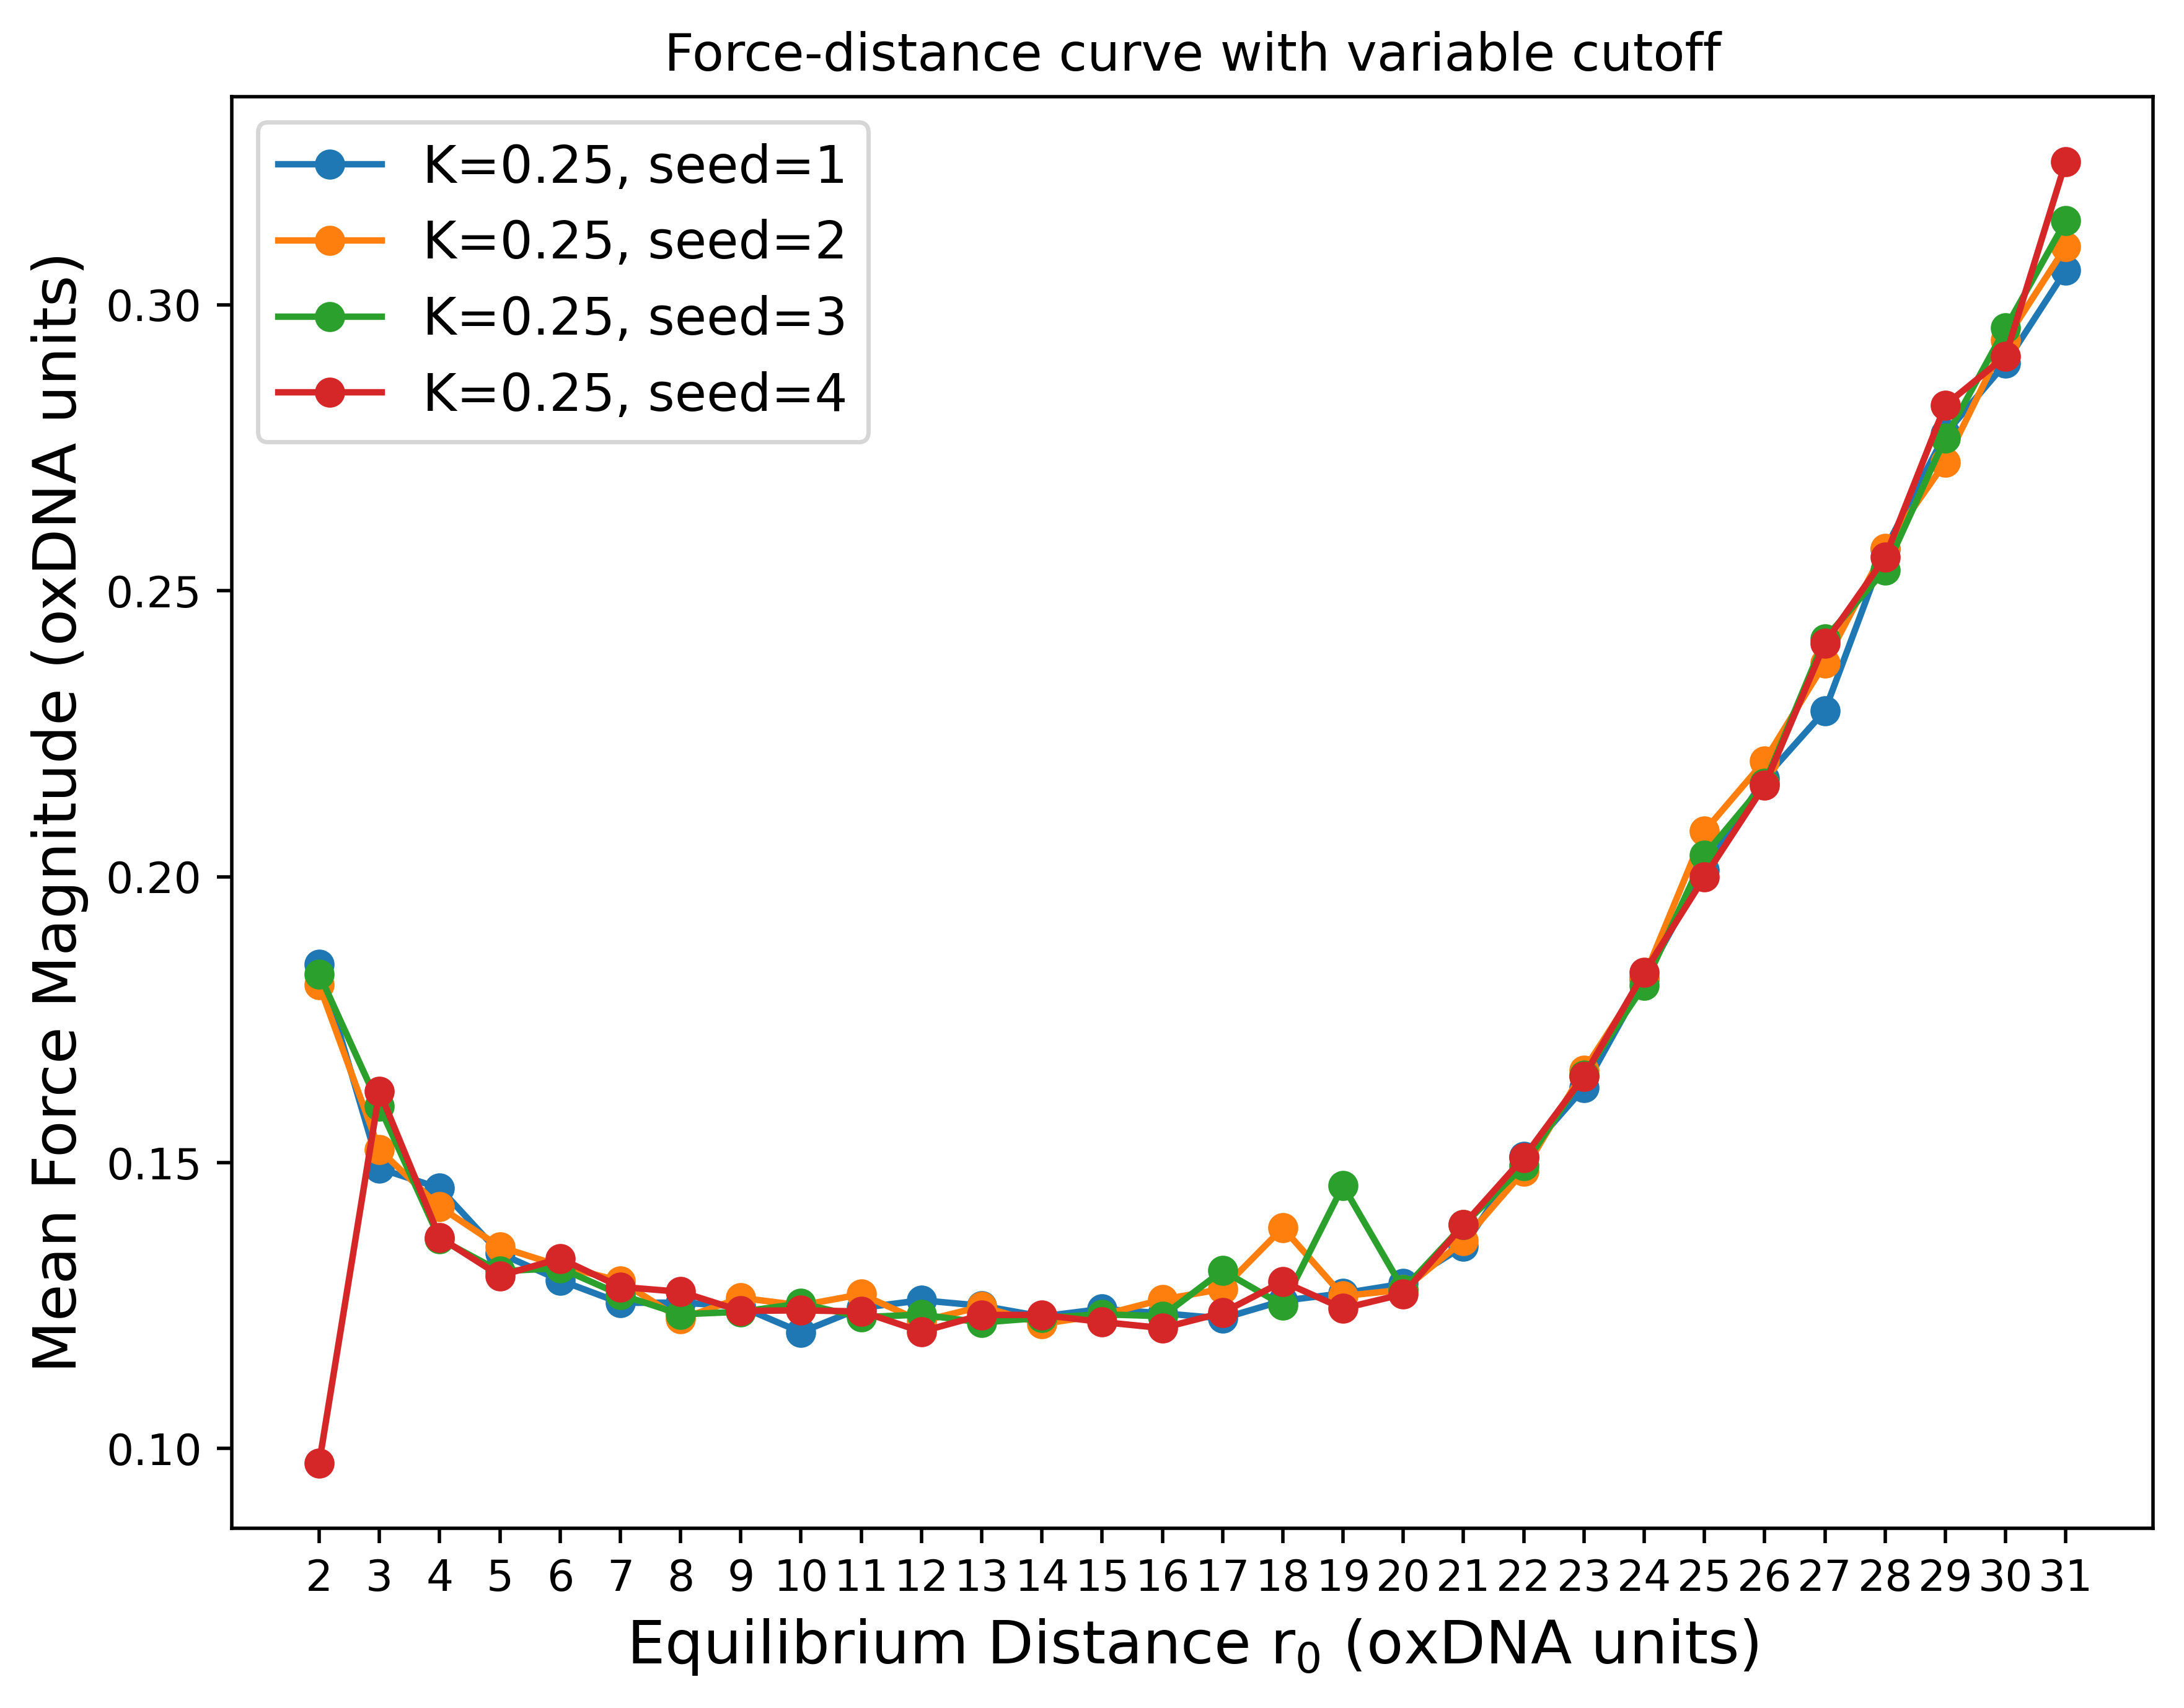

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8,6), dpi=500)

for k, label in [(0.25, "K=0.25")]:
    sub_k = stats_df[stats_df["k"] == k]
    for s in sorted(sub_k["seed"].unique()):
        sub = sub_k[sub_k["seed"] == s].sort_values("r_0")
        ax.plot(sub["r_0"], sub["|F| mean"], marker="o", label=f"{label}, seed={s}")
ax.set_xticks(r0_values)
ax.set_xlabel(r"Equilibrium Distance r$_0$ (oxDNA units)", fontsize=14)
ax.set_ylabel("Mean Force Magnitude (oxDNA units)", fontsize=14)
ax.set_title("Force-distance curve with variable cutoff")
ax.legend(fontsize=12)

plt.show()

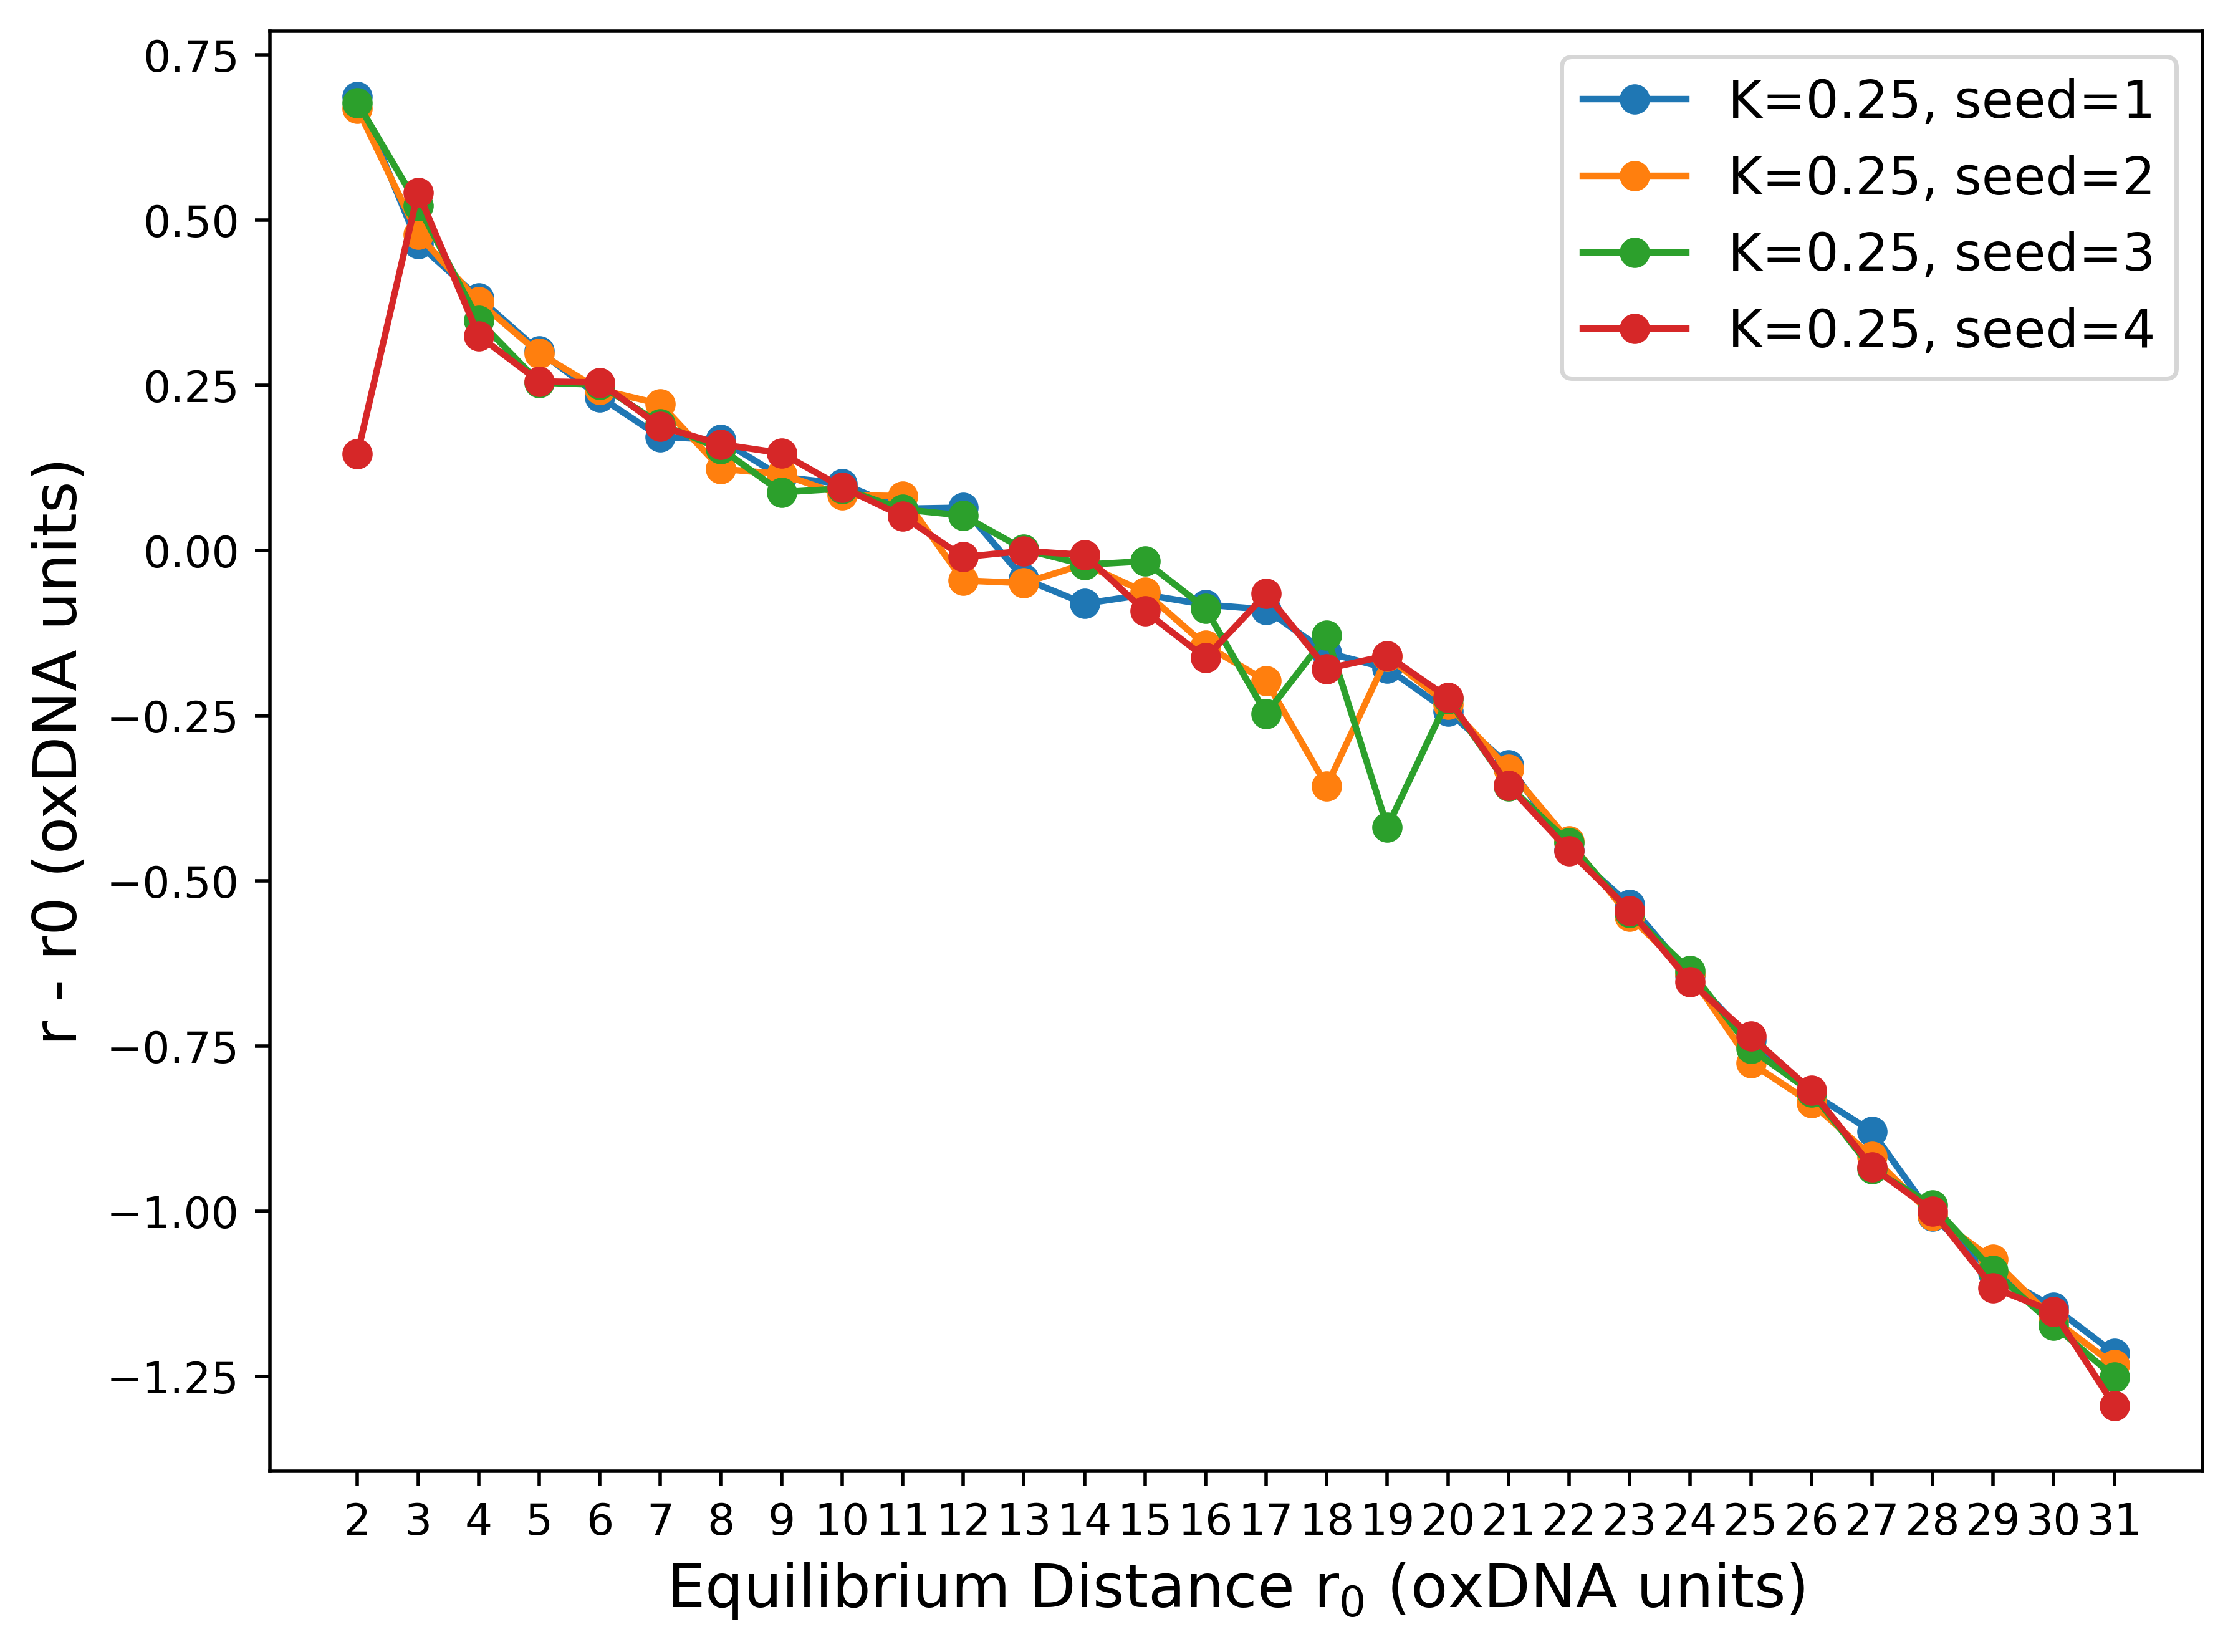

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8,6), dpi=500)

for k, label in [(0.25, "K=0.25")]:
    sub_k = stats_df[stats_df["k"] == k]
    for s in sorted(sub_k["seed"].unique()):
        sub = sub_k[sub_k["seed"] == s].sort_values("r_0")
        y = sub["dist mean"] - sub["r_0"]
        ax.plot(sub["r_0"], y, marker="o", label=f"{label}, seed={s}")
ax.set_xticks(r0_values)
ax.set_xlabel(r"Equilibrium Distance r$_0$ (oxDNA units)", fontsize=14)
ax.set_ylabel("r - r0 (oxDNA units)", fontsize=14)
ax.legend(fontsize=12)

plt.show()

In [ ]:
CUTOFF = 2.5e7  # 2,500,000

dfs_cfiltered = {}  # dfs_cfiltered[k][r0][seed] = cutoff-filtered df

for k, by_r0 in dfs.items():
    dfs_cfiltered[k] = {}
    for r0, by_seed in by_r0.items():
        dfs_cfiltered[k][r0] = {}
        for s, df in by_seed.items():
            dfs_cfiltered[k][r0][s] = df[df["step"] >= CUTOFF].reset_index(drop=True)

In [ ]:
#### BASIC STATISTICS OF STEADY STATE REGION
import numpy as np
import pandas as pd

stats_data = []
for k, by_r0 in dfs_cfiltered.items():
    for r0 in r0_values:
        if r0 not in by_r0:
            continue
        for s, df in by_r0[r0].items():

            # signed force: +|F| if dist > r0, -|F| if dist < r0
            # np.sign gives -1, 0, +1; equality -> 0 (force becomes 0 at exact r0)
            signed_force = np.sign(df["dist"].to_numpy() - r0) * df["force_mag"].to_numpy()

            stats_data.append({
                "k": k,
                "r_0": float(r0),
                "seed": int(s),

                "F mean": signed_force.mean(),
                "F std": signed_force.std(ddof=0),

                "|F| mean": df["force_mag"].mean(),
                "|F| std": df["force_mag"].std(ddof=0),

                "dist mean": df["dist"].mean(),
                "dist std": df["dist"].std(ddof=0),
                "hbonds mean": df["hbond"].mean(),
            })

stats_df = pd.DataFrame(stats_data).sort_values(["k", "r_0", "seed"])
print(stats_df)

        k   r_0  seed    F mean     F std  |F| mean   |F| std  dist mean  \
0    0.25   2.0     1  0.172228  0.137531  0.184910  0.119939   2.688911   
1    0.25   2.0     2  0.166226  0.136903  0.180069  0.118104   2.664904   
2    0.25   2.0     3  0.170736  0.137599  0.184021  0.119249   2.682945   
3    0.25   2.0     4  0.049298  0.121658  0.106765  0.076369   2.197190   
4    0.25   3.0     1  0.116001  0.144335  0.149577  0.109158   3.464004   
..    ...   ...   ...       ...       ...       ...       ...        ...   
115  0.25  30.0     4 -0.288969  0.148143  0.291863  0.142357  28.844122   
116  0.25  31.0     1 -0.302730  0.150174  0.305098  0.145303  29.789081   
117  0.25  31.0     2 -0.312913  0.151502  0.315065  0.146972  29.748350   
118  0.25  31.0     3 -0.312115  0.149112  0.314094  0.144897  29.751542   
119  0.25  31.0     4 -0.314660  0.151436  0.316719  0.147082  29.741358   

     dist std  hbonds mean  
0    0.550123    47.223391  
1    0.547610    47.047256  


C:\Users\Tristan\AppData\Local\Temp\ipykernel_9300\2783019263.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=12)


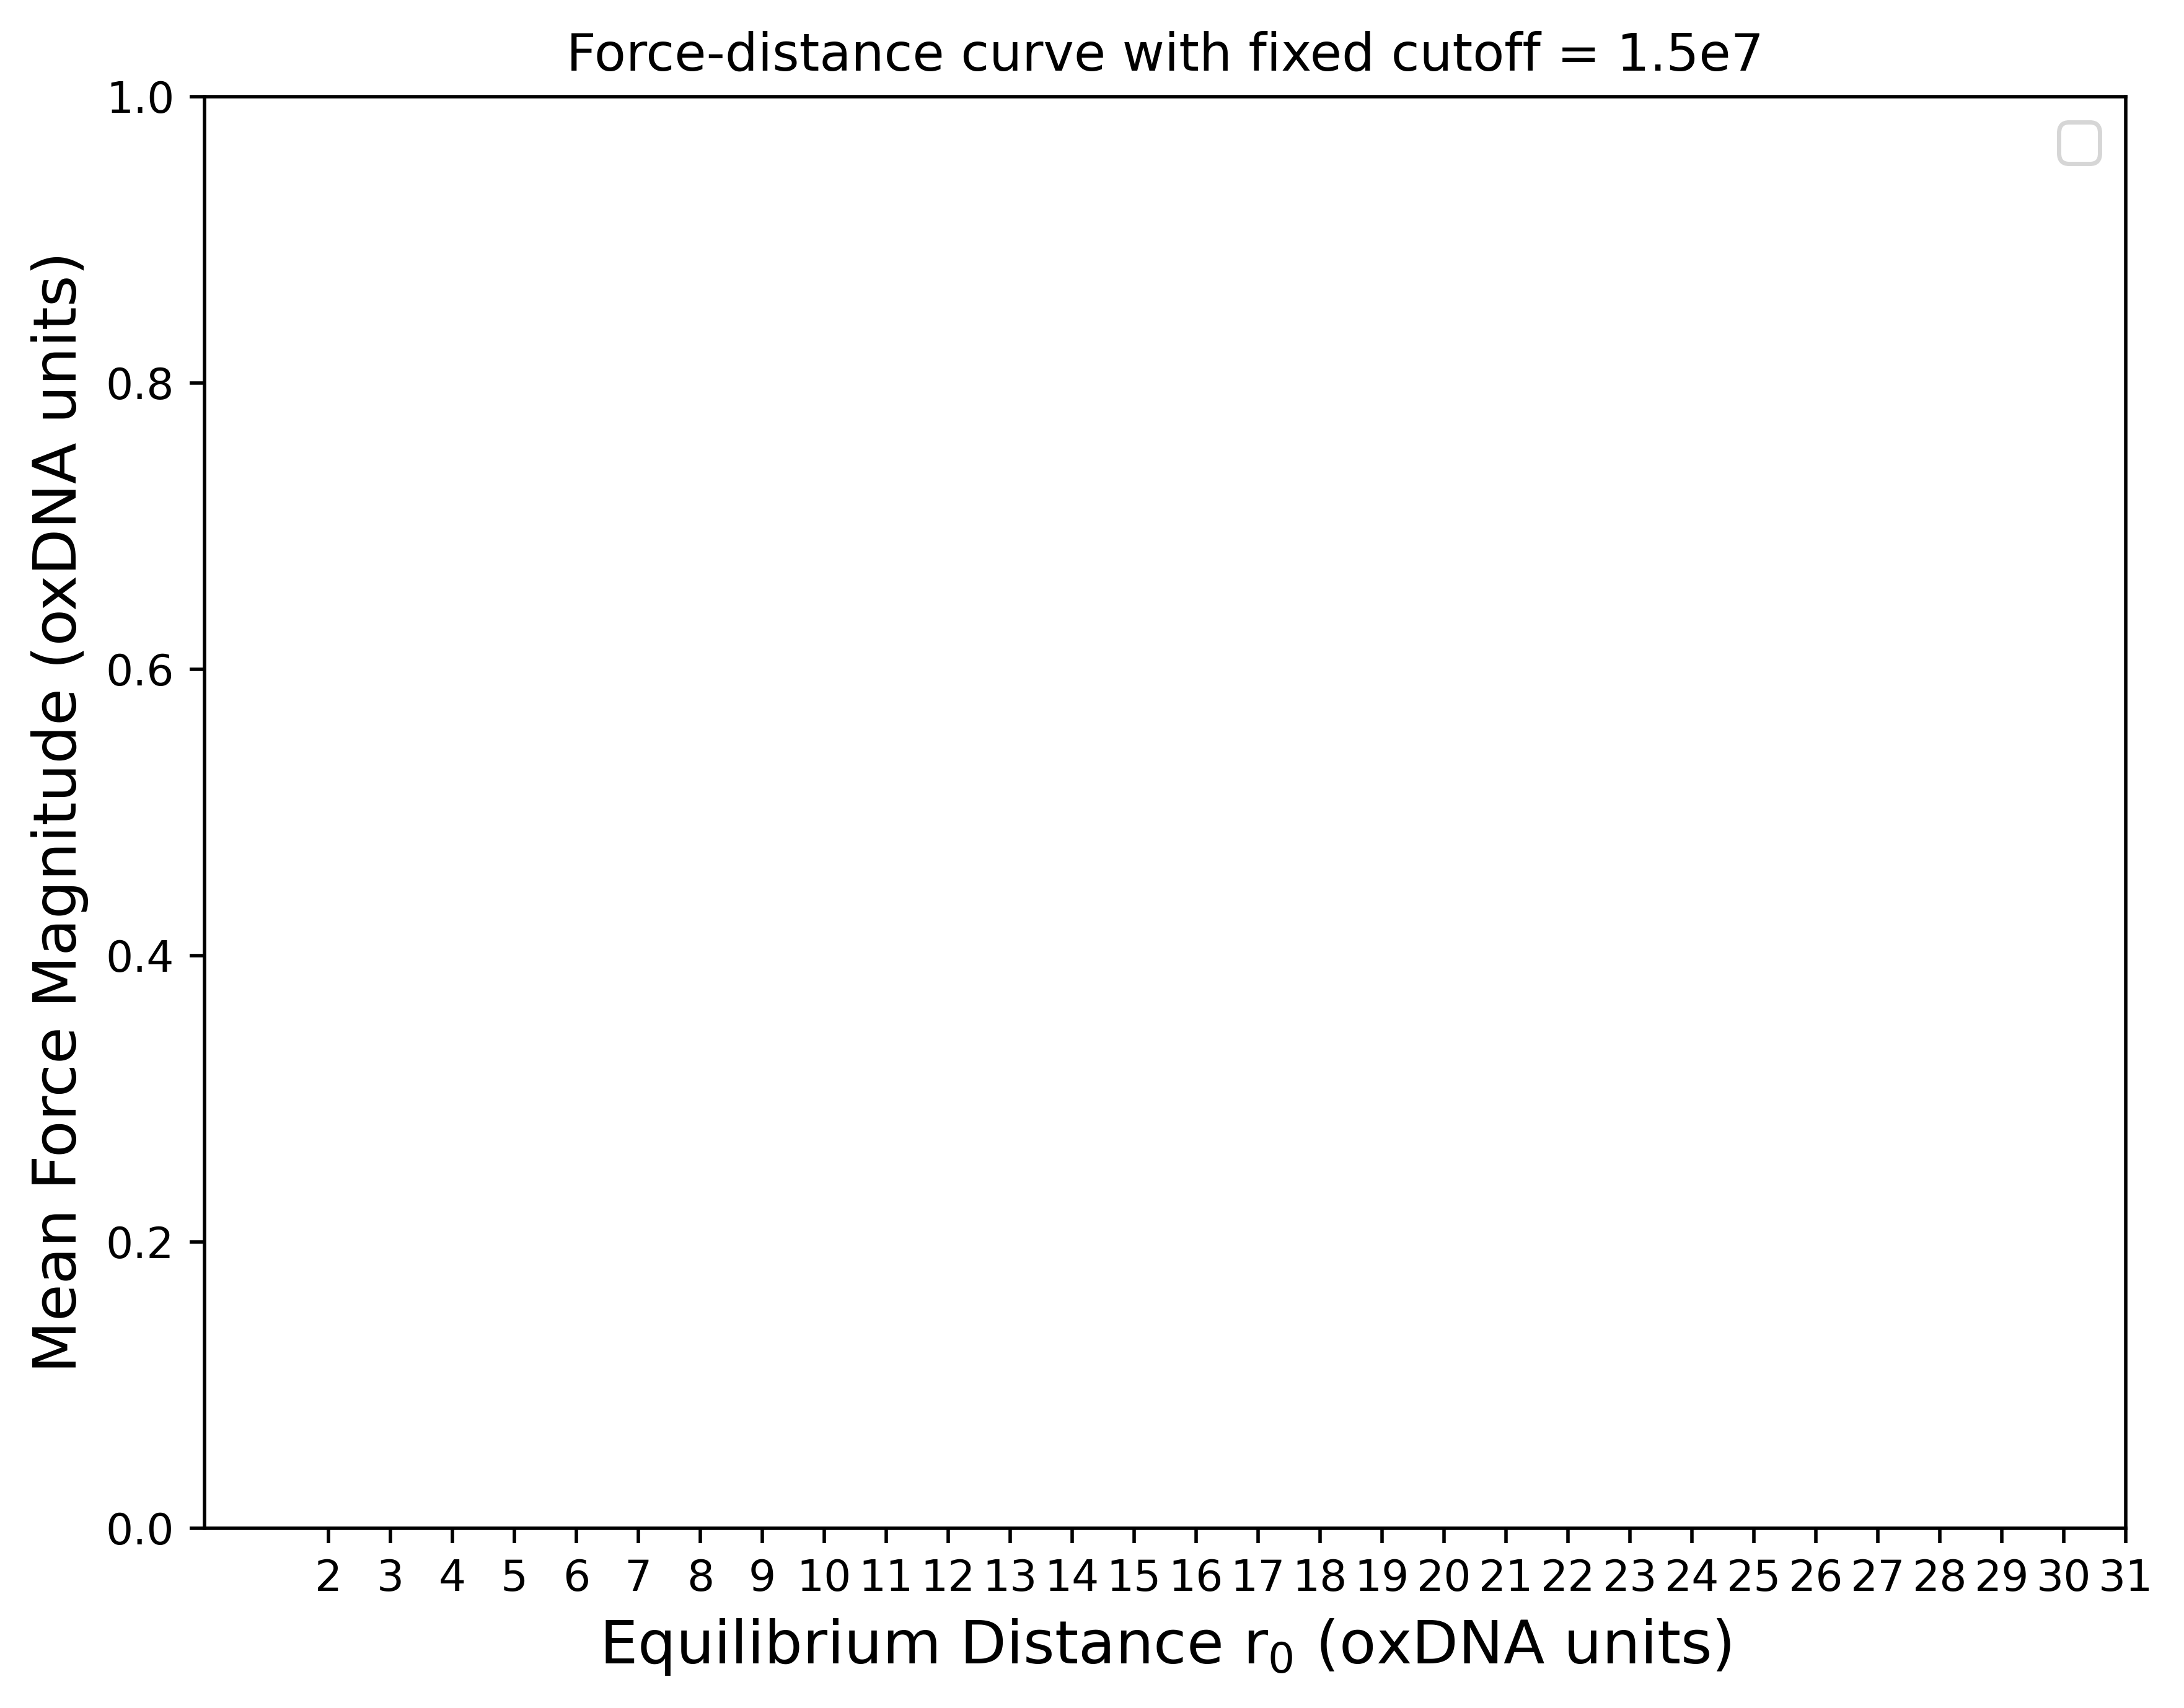

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8,6), dpi=500)

for k, label in [(0.35, "K=0.35"), (0.45, "K=0.45")]:
    sub_k = stats_df[stats_df["k"] == k]
    for s in sorted(sub_k["seed"].unique()):
        sub = sub_k[sub_k["seed"] == s].sort_values("r_0")
        ax.plot(sub["r_0"], sub["|F| mean"], marker="o", label=f"{label}, seed={s}")
ax.set_xticks(r0_values)
ax.set_xlabel(r"Equilibrium Distance r$_0$ (oxDNA units)", fontsize=14)
ax.set_ylabel("Mean Force Magnitude (oxDNA units)", fontsize=14)
ax.set_title("Force-distance curve with fixed cutoff = 1.5e7")
ax.legend(fontsize=12)

plt.show()

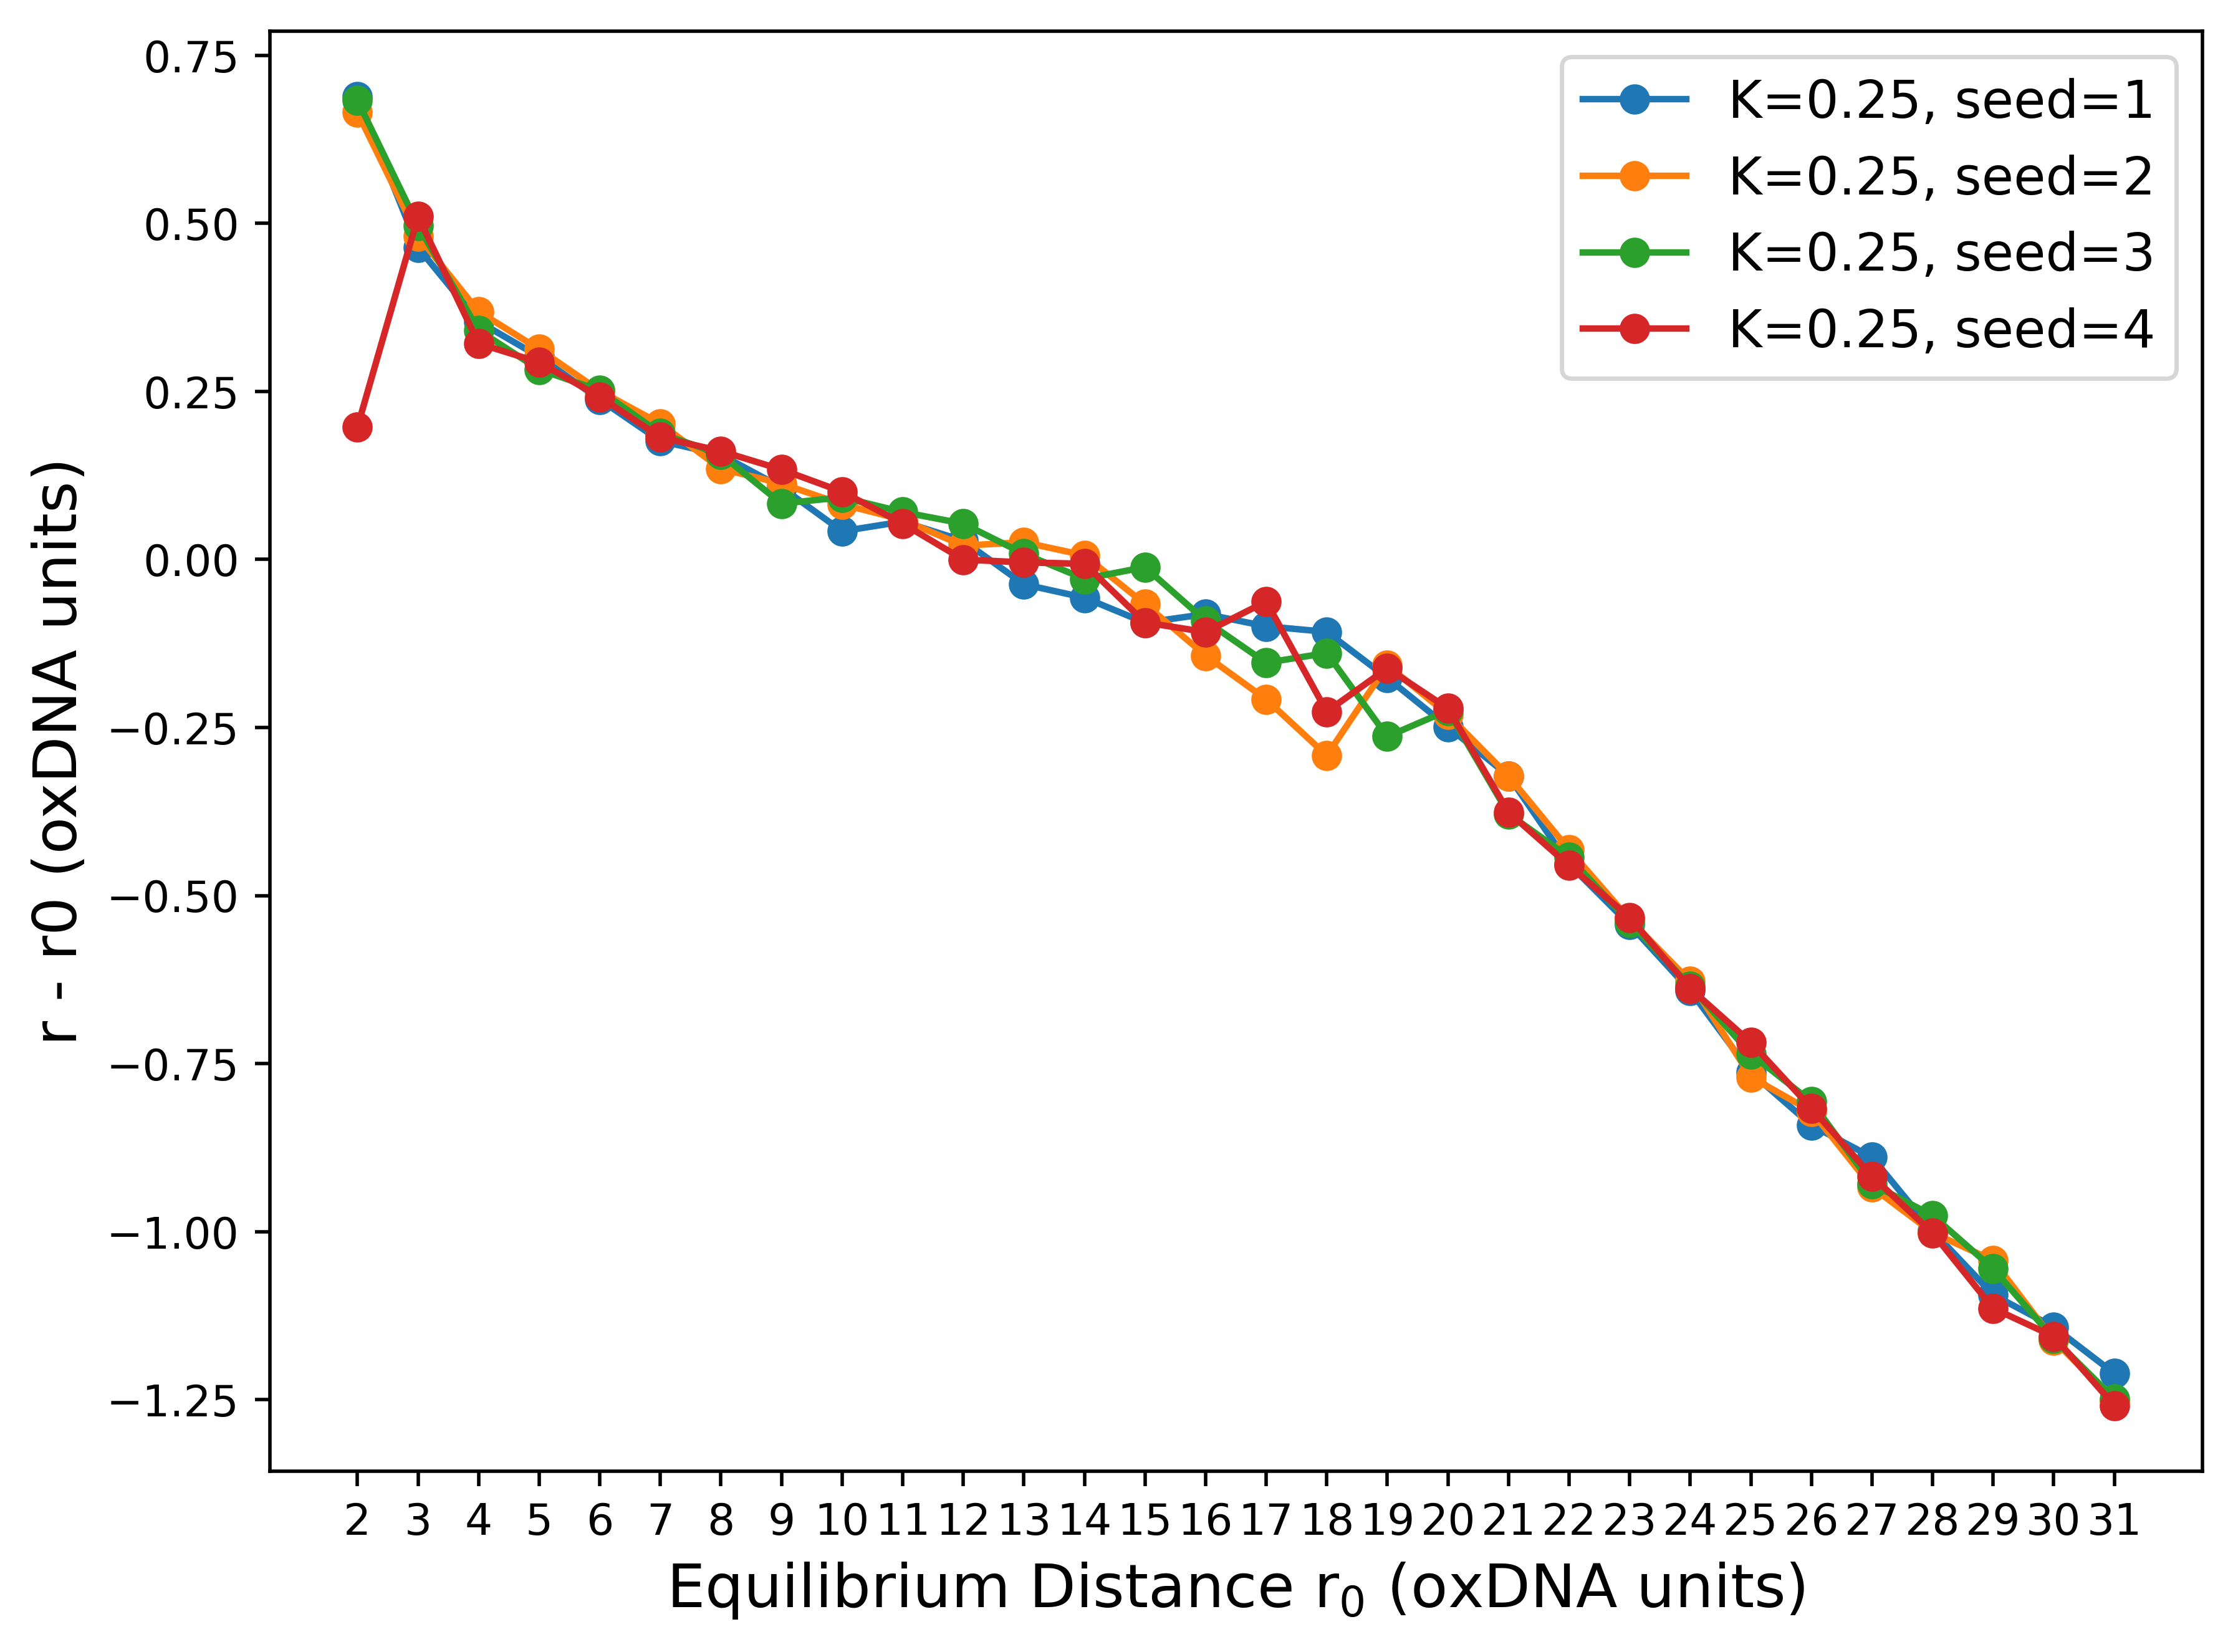

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8,6), dpi=500)

for k, label in [(0.25, "K=0.25"), (0.45, "K=0.45")]:
    sub_k = stats_df[stats_df["k"] == k]
    for s in sorted(sub_k["seed"].unique()):
        sub = sub_k[sub_k["seed"] == s].sort_values("r_0")
        y = sub["dist mean"] - sub["r_0"]
        ax.plot(sub["r_0"], y, marker="o", label=f"{label}, seed={s}")
ax.set_xticks(r0_values)
ax.set_xlabel(r"Equilibrium Distance r$_0$ (oxDNA units)", fontsize=14)
ax.set_ylabel("r - r0 (oxDNA units)", fontsize=14)
ax.legend(fontsize=12)

plt.show()

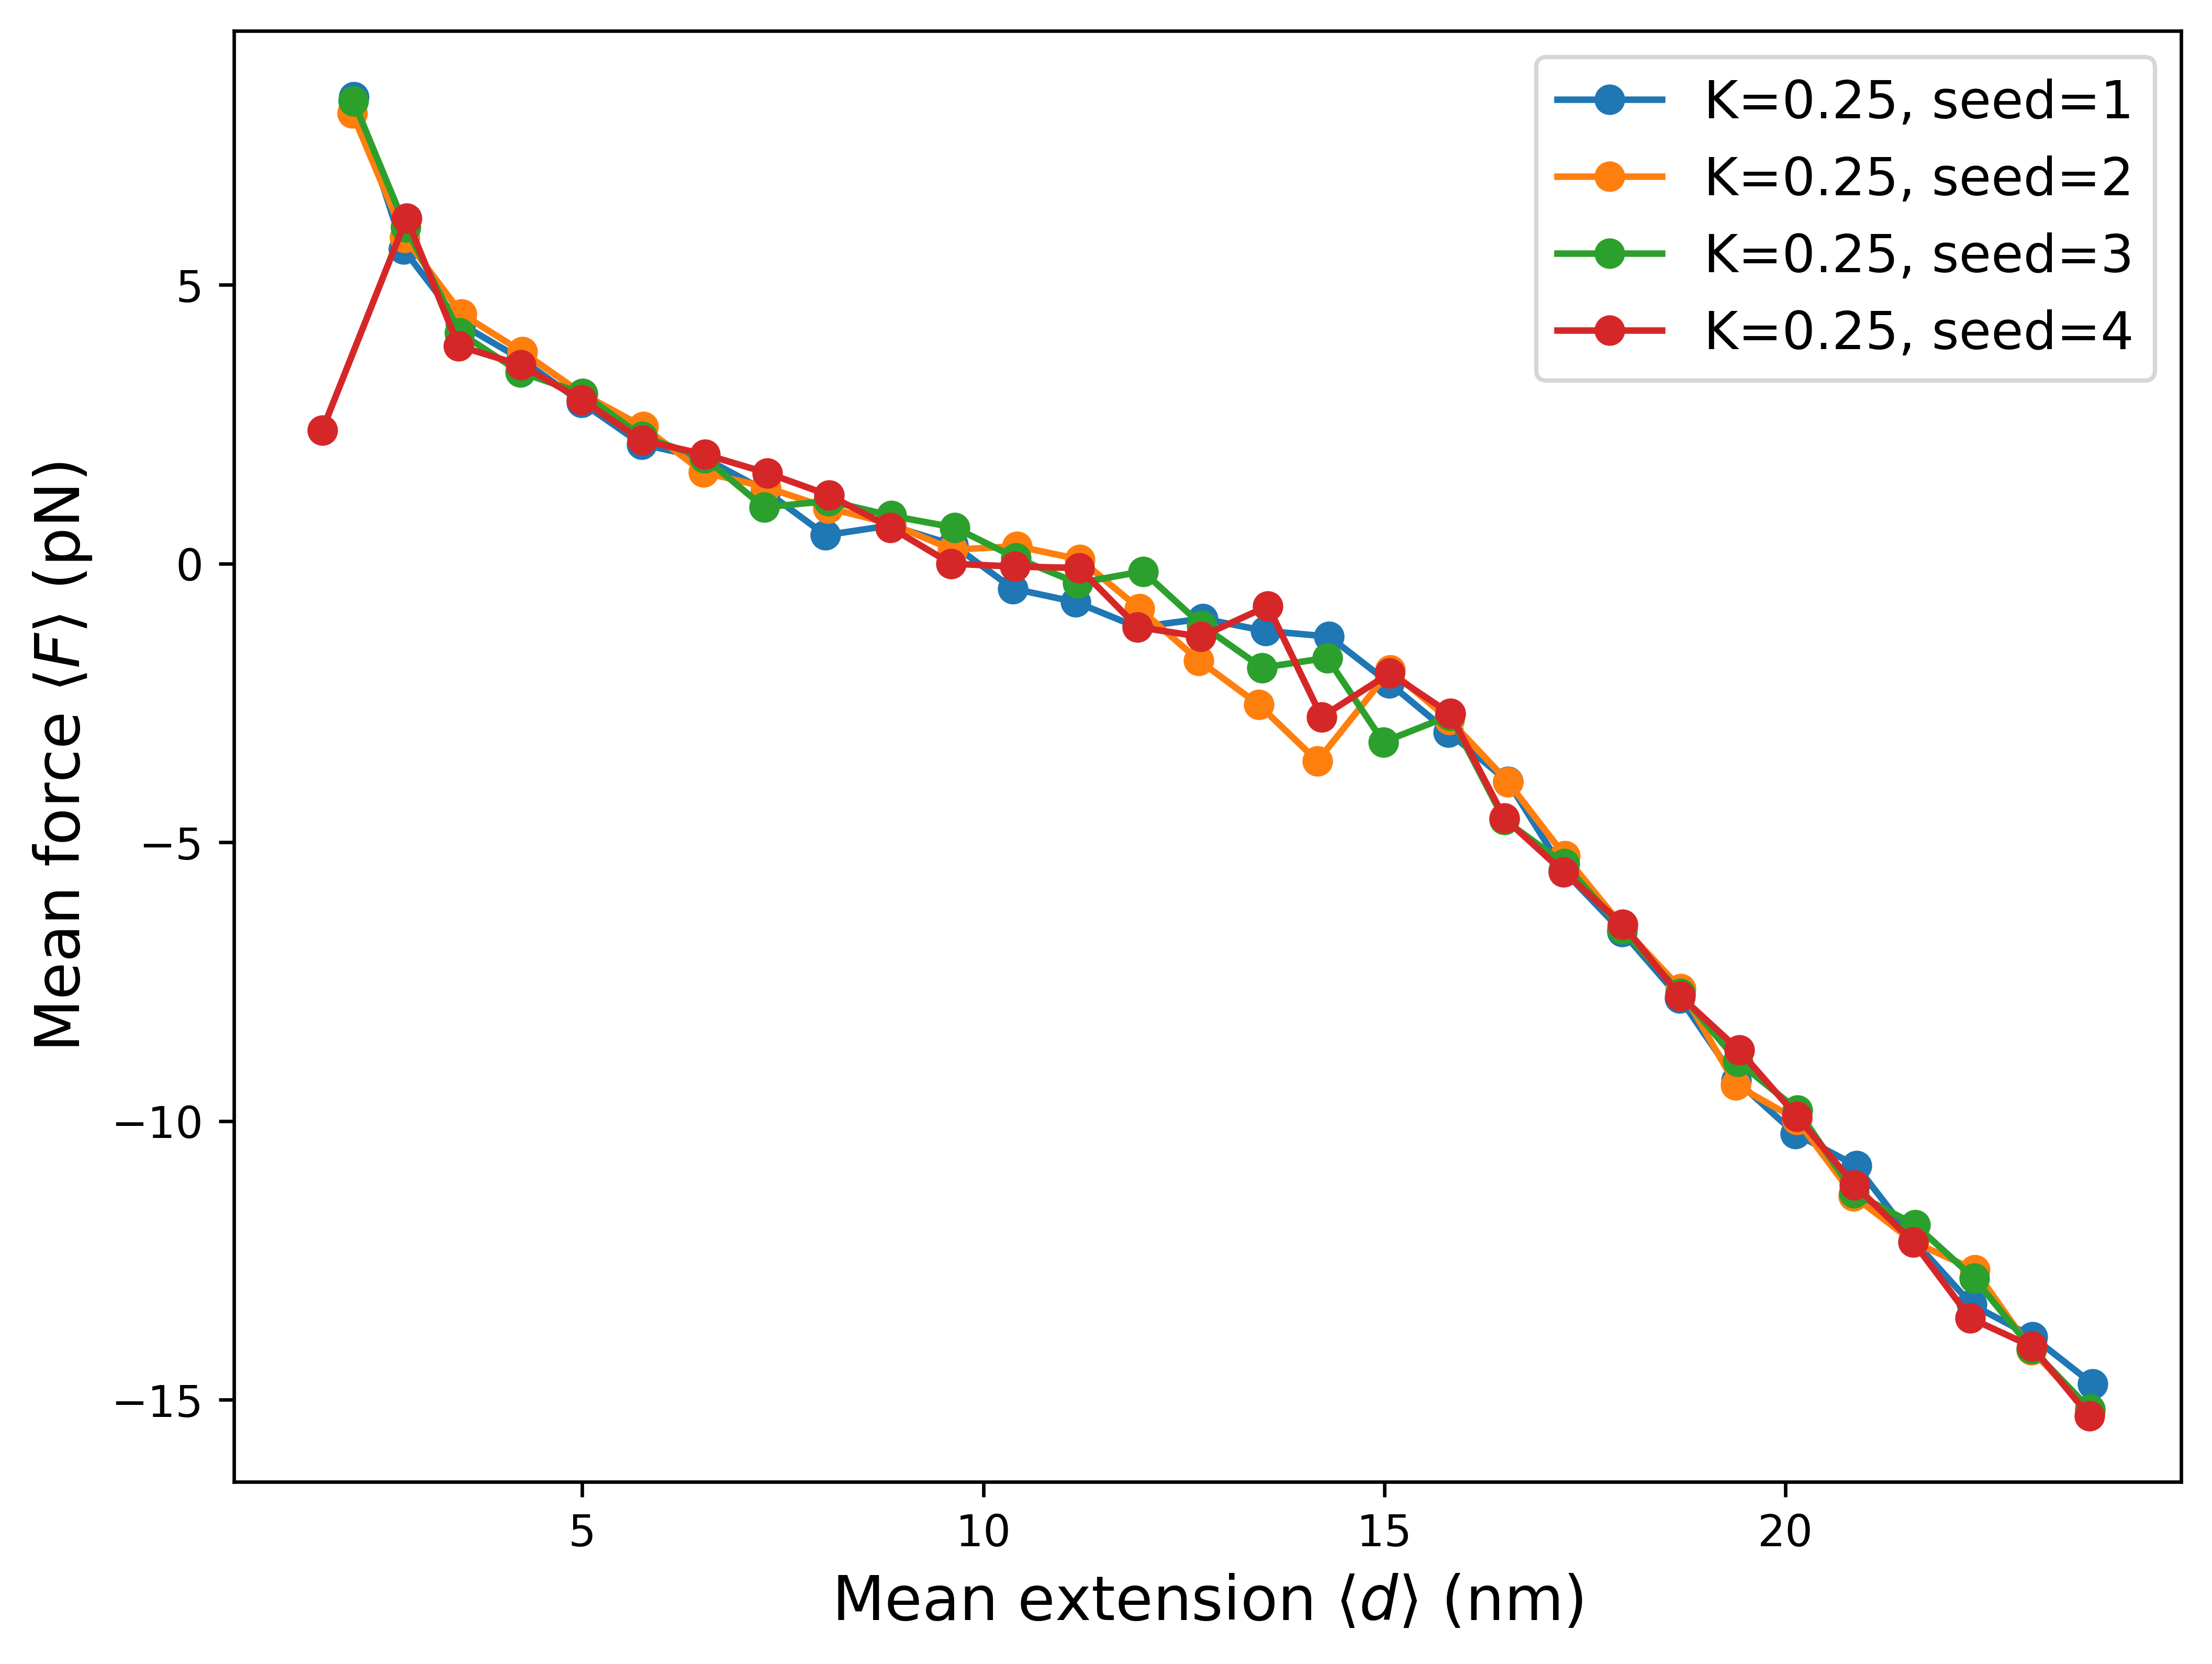

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6), dpi=600)

for k, label in [(0.25, "K=0.25")]:
    sub_k = stats_df[stats_df["k"] == k]
    for s in sorted(sub_k["seed"].unique()):
        sub = sub_k[sub_k["seed"] == s].sort_values("dist mean")
        ax.plot(0.8*sub["dist mean"], 48.6*sub["F mean"], marker="o", label=f"{label}, seed={s}")

ax.set_xlabel(r"Mean extension $\langle d \rangle$ (nm)", fontsize=14)
ax.set_ylabel(r"Mean force $\langle F \rangle$ (pN)", fontsize=14)
ax.legend(fontsize=12)

plt.show()